# Projet Data Science en nutrition humaine 

Les étapes d’un tel projet sont les suivantes : 
1. Formuler le problème scientifique dans un langage clair et facilement compréhensible. 
Donner des exemples de questions auxquelles ce projet peut répondre. 
2. Identifier les données disponibles. 
a. Évaluer leur volumétrie et leur qualité.  
b. Établir pour chaque jeu de données une fiche d’identification.  
c. Choisir les jeux de données qui seront utilisés pour le projet. 
3. Data engineering :  
a. Charger,  nettoyer,  explorer  et  visualiser  les  données  ;  les  organiser  dans  un 
modèle relationnel 
b. Gestion des valeurs manquantes 
c. Représentativité de l’échantillon et pondérations d’enquête 
d. Confidentialité (RGPD, données pseudonymisées) 
e. Biais de sélection et de déclaration (par exemple sous-déclaration des apports) 
4. Proposer  des  indicateurs  ainsi  que  les  méthodes  statistiques  ou  d’apprentissage 
automatique (ML) permettant de répondre aux questions identifiées à la première étape.  
5. Présenter les résultats et leur interprétation. 
6. Donner des arguments pour justifier 
a. Le choix des métriques 
b. La validation des méthodes choisies et la robustesse des résultats 
c. La reproductibilité du pipeline 
d. La traçabilité des données

## 1. Objectif :
**« Comment se caractérisent les consommations alimentaires et les apports 
nutritionnels de la population française, comment varient-ils selon l’âge et le sexe, et quels 
aliments y contribuent le plus ? »**  

Cette analyse permettra de répondre, par exemple, aux questions suivantes : 
- Quels sont les apports énergétiques moyens ?  
- Comment varient-ils selon l'âge et le sexe ?  
- Quels aliments contribuent le plus aux apports en protéines, calcium, fer, fibres, etc. ?  
- Quelle est la variabilité interindividuelle ?  
- Existe-t-il différents profils alimentaires ?  
- Comment comparer plusieurs enquêtes alimentaires ?  

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats


## 2. La pipeline_Data Engineering

### a. Traitement des csv disponibles

**Regler le prbl des individus présent uniquement dans certaines tables :**  
On a 5855 individus dans `description-indiv.csv` initiallement, mais uniquement 4013 individus commun à toutes les tables. On en conserve donc une grosse parti et on va donc traiter les données uniquemens sur les lignes en commun (ca devrait enlever des cas compliqués sur des na ...)

In [5]:
d_descri = pd.read_csv("tables/description-indiv.csv", sep=";", low_memory=False) #, low_memory=False uniquement pour supprimer le warning sur les colonnes de type object (colonnes qu'on supprime après de tte manière)
d_gpe = pd.read_csv("tables/conso-gpe-inca3.csv", sep=";")
d_app = pd.read_csv("tables/apports-nut-alim.csv", sep=";")
d_hab = pd.read_csv("tables/habitudes-indiv.csv", sep=";", low_memory=False)

noind_communs = set(d_gpe['NOIND']) & set(d_app['NOIND']) & set(d_hab['NOIND']) & set(d_descri['NOIND'])

print(f"Nombre d'individus dans description-indiv.csv : {len(d_descri)}")
print(f"Nombre d'individus dans conso-gpe-inca3.csv : {len(d_gpe)}")
print(f"Nombre d'individus dans apports-nut-alim.csv : {len(d_app)}")
print(f"Nombre d'individus dans habitudes-indiv.csv : {len(d_hab)}")
print(f"Nombre total d'individus communs : {len(noind_communs)}")

df = (
    d_descri[d_descri["NOIND"].isin(noind_communs)]
    .merge(
        d_gpe[d_gpe["NOIND"].isin(noind_communs)],
        on="NOIND",
        how="inner",
        suffixes=("_descri", "_gpe")
    )
    .merge(
        d_app[d_app["NOIND"].isin(noind_communs)],
        on=["NOIND", "POPULATION"],          # Conso_gpe et apports ont chacun une colonne POPULATION
        how="inner",
        suffixes=("", "_app")
    )
    # .merge(
    #     d_hab[d_hab["NOIND"].isin(noind_communs)],
    #     on="NOIND",
    #     how="inner",
    #     suffixes=("", "_hab")
    # )
)


Nombre d'individus dans description-indiv.csv : 5855
Nombre d'individus dans conso-gpe-inca3.csv : 4114
Nombre d'individus dans apports-nut-alim.csv : 4114
Nombre d'individus dans habitudes-indiv.csv : 4372
Nombre total d'individus communs : 4013


**Regler le prbl des colonnes str :**  
On a 8 colonnes str :
- `zae` : on supprime juste le Z d'entete et ca devient un int c'est good
- les colonnes finissant par `*_libelle` ne contiennent que peut d'information, et c'est des choses rentrées à la main par les personnes $\to$ on ne se prend pas la tête pour une étude large et on en tiens pas compte = suppression

In [6]:
nb_str = len(df.select_dtypes(include=['object', 'string']).columns)
nb_num = len(df.select_dtypes(include=['number']).columns)

print("--- Décompte des types de colonnes ---")
print(f"Nombre de colonnes au format texte (str) : {nb_str}")
print(f"Nombre de colonnes au format numérique (int/float) : {nb_num}")
print('\n')

d_str = df.select_dtypes(include=['object', 'string'])
for k in d_str.columns:
    print(f"Colonne '{k}' : {d_str[k].nunique()} valeurs uniques, {d_str[k].isna().sum()} valeurs manquantes")
    # print(d_str[k].unique())

df["zae"] = df["zae"].str[1:].astype("Int64") # Z78267 -> 78267
colonnes_libelle = df.columns[df.columns.str.endswith("_libelle")]
df.drop(columns=colonnes_libelle, inplace=True) # supprimer les colonnes *_libelles, les raisons du oui à la colonne d'avant, annecdotique pour nous

--- Décompte des types de colonnes ---
Nombre de colonnes au format texte (str) : 9
Nombre de colonnes au format numérique (int/float) : 327


Colonne 'zae' : 181 valeurs uniques, 0 valeurs manquantes
Colonne 'regime_raisonmed_libelle' : 101 valeurs uniques, 3853 valeurs manquantes
Colonne 'veget_autre_alim_libelle' : 1 valeurs uniques, 4012 valeurs manquantes
Colonne 'allergie_fruitcoque_libelle' : 12 valeurs uniques, 3997 valeurs manquantes
Colonne 'allergie_autres_fl_libelle' : 27 valeurs uniques, 3979 valeurs manquantes
Colonne 'allergie_autresalim_libelle' : 15 valeurs uniques, 1956 valeurs manquantes
Colonne 'regime_type_libelle' : 23 valeurs uniques, 3936 valeurs manquantes
Colonne 'poids_modifalim_autre_libelle' : 21 valeurs uniques, 3956 valeurs manquantes
Colonne 'POPULATION' : 1 valeurs uniques, 0 valeurs manquantes


**Affichage graphique des valeurs manquantes avant et après nettoyage des colonnes str**

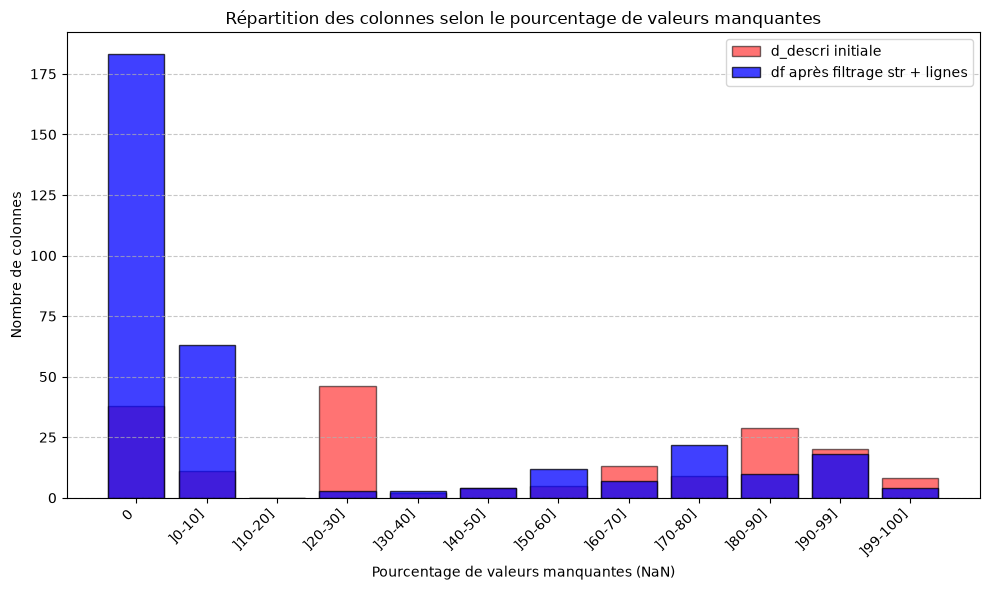

In [7]:
# Pourcentage de valeurs manquantes dans les deux tables
nan_descri = d_descri.isna().mean() * 100
nan_df = df.isna().mean() * 100

bins = [-0.01, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 99, 100.01]
labels = [
    '0', ']0-10]', ']10-20]', ']20-30]', ']30-40]', ']40-50]',
    ']50-60]', ']60-70]', ']70-80]', ']80-90]', ']90-99]', ']99-100]'
]

counts_descri = pd.cut(
    nan_descri, bins=bins, labels=labels
).value_counts(sort=False)

counts_df = pd.cut(
    nan_df, bins=bins, labels=labels
).value_counts(sort=False)

x = np.arange(len(labels))

plt.figure(figsize=(10, 6))

# Table d_descri en arrière-plan
plt.bar(
    x, counts_descri.values,
    color='red', alpha=0.55,
    edgecolor='black', label='d_descri initiale'
)

# Table df au premier plan
plt.bar(
    x, counts_df.values,
    color='blue', alpha=0.75,
    edgecolor='black', label='df après filtrage str + lignes'
)

plt.title("Répartition des colonnes selon le pourcentage de valeurs manquantes")
plt.xlabel("Pourcentage de valeurs manquantes (NaN)")
plt.ylabel("Nombre de colonnes")
plt.xticks(x, labels, rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()

# plt.savefig("graphs/nan_distribution_comparaison.png")
plt.show()

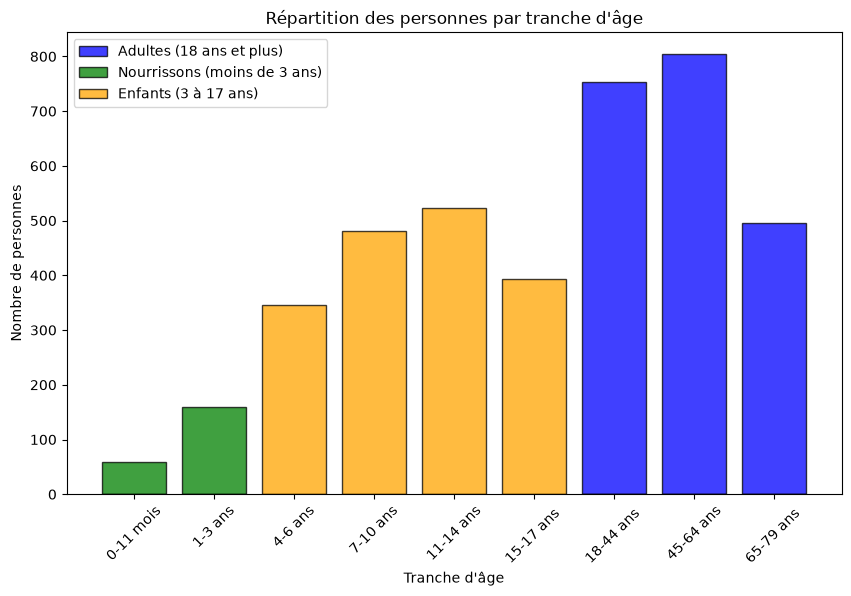

In [8]:
df_adulte = df[df["tage_PS"] >= 7]
df_nourisson = df[df["tage_PS"] < 3]
df_enfant = df[(df["tage_PS"] >= 3) & (df["tage_PS"] < 7)]

bins = [0,1,2,3,4,5,6,7,8,9]
labels = ['0-11 mois', '1-3 ans', '4-6 ans', '7-10 ans', '11-14 ans', '15-17 ans ', '18-44 ans ', '45-64 ans', '65-79 ans ']

counts_adulte = pd.cut(df_adulte["tage_PS"], bins=bins, labels=labels)
counts_nourisson = pd.cut(df_nourisson["tage_PS"], bins=bins, labels=labels)
counts_enfant = pd.cut(df_enfant["tage_PS"], bins=bins, labels=labels)

x = np.arange(len(labels))

plt.figure(figsize=(10, 6))
plt.bar(x, counts_adulte.value_counts(sort=False), color='blue', alpha=0.75, edgecolor='black', label='Adultes (18 ans et plus)')
plt.bar(x, counts_nourisson.value_counts(sort=False), color='green', alpha=0.75, edgecolor='black', label='Nourrissons (moins de 3 ans)')
plt.bar(x, counts_enfant.value_counts(sort=False), color='orange', alpha=0.75, edgecolor='black', label='Enfants (3 à 17 ans)')
plt.xlabel('Tranche d\'âge')
plt.ylabel('Nombre de personnes')
plt.title('Répartition des personnes par tranche d\'âge')
plt.xticks(x, labels, rotation=45)
plt.legend()
plt.show()


**Regler le problèmes des valeurs manquantes :**  
- Colonnes vides = suppression
- très peu de valeurs manquantes (<1% par exemple) = suppresion ligne
- bcp valeur manquantes : verification si c'est pas juste un 0 non encodé, ou resoudre le prbl. Si pas possible = ecarter la colonne
- Valeurs manquantes = "Non applicable" : la valeur manquante ne signifie pas un oublie ou un non, par exemple si on a repondu être un homme, il est logique qu'il n'y ai rien dans enceinte, répondre "non" est une information innatendue. Il faut imputer "non applicable"

--- Adultes ---
Adultes : 7 colonne(s) vide supprimée(s)
Colonne 'diplome_interv' : 12 valeurs uniques, 0.05% de valeurs manquantes
Colonne 'atrav_interv' : 2 valeurs uniques, 53.77% de valeurs manquantes
Colonne 'trav_nuit_interv' : 4 valeurs uniques, 46.23% de valeurs manquantes
Colonne 'trav_nuit_2cl_interv' : 2 valeurs uniques, 46.23% de valeurs manquantes
Colonne 'tps_travail_interv' : 2 valeurs uniques, 3.75% de valeurs manquantes
Colonne 'lien_interv_PR' : 4 valeurs uniques, 65.32% de valeurs manquantes
Colonne 'lien_PS_PR' : 4 valeurs uniques, 65.32% de valeurs manquantes
Colonne 'diplome_PR' : 14 valeurs uniques, 0.10% de valeurs manquantes
Colonne 'atrav_PR' : 3 valeurs uniques, 55.92% de valeurs manquantes
Colonne 'tps_travail_PR' : 2 valeurs uniques, 1.61% de valeurs manquantes
Colonne 'RUC_4cl' : 4 valeurs uniques, 7.65% de valeurs manquantes
Colonne 'IA_score' : 6 valeurs uniques, 86.60% de valeurs manquantes
Colonne 'taille_m' : 51 valeurs uniques, 4.38% de valeurs manqu

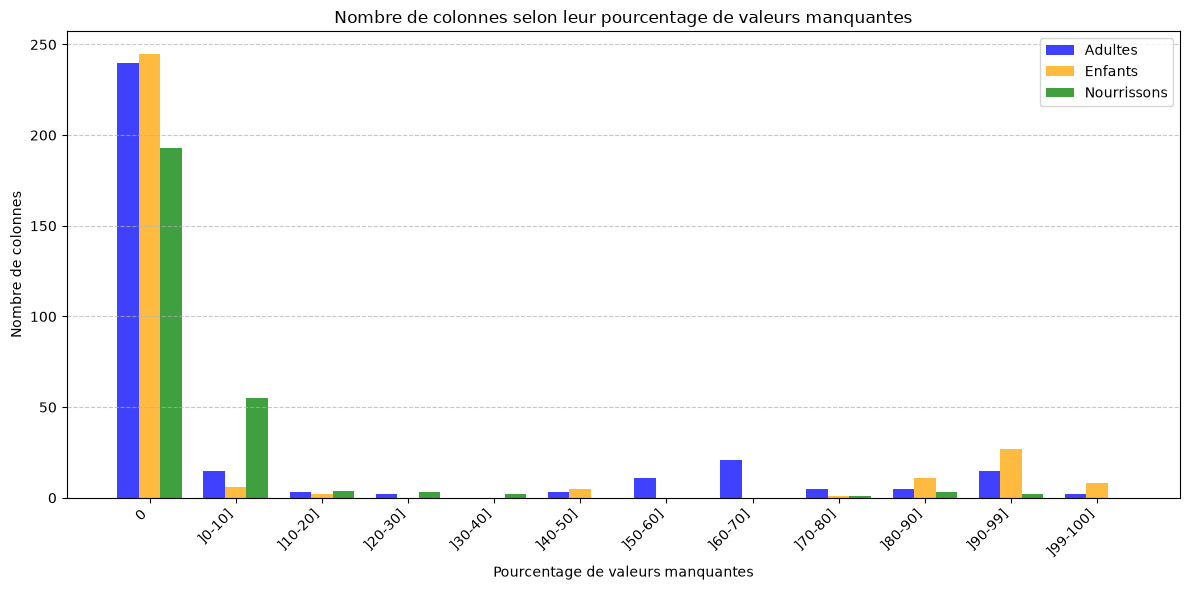

In [9]:
dfs = {
    "Adultes": df_adulte,
    "Enfants": df_enfant,
    "Nourrissons": df_nourisson
}

for nom, data in dfs.items():
    # 1. Supprimer les colonnes vides
    colonnes_vides = data.columns[data.isna().all()]
    data.drop(columns=colonnes_vides, inplace=True)

    # 2. Afficher les informations sur les colonnes restantes
    print(f"--- {nom} ---")
    print(f"{nom} : {len(colonnes_vides)} colonne(s) vide supprimée(s)")
    for k in data.columns:
        if data[k].isna().sum() > 0:
            print(
                f"Colonne '{k}' : "
                f"{data[k].nunique()} valeurs uniques, "
                f"{data[k].isna().sum()/len(data)*100:.2f}% de valeurs manquantes"
            )
    print('\n')



# Pourcentage de valeurs manquantes par colonne
bins = [-0.01, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 99, 100.01]
labels = [
    "0", "]0-10]", "]10-20]", "]20-30]", "]30-40]", "]40-50]",
    "]50-60]", "]60-70]", "]70-80]", "]80-90]", "]90-99]", "]99-100]"
]

comptages = {}

for nom, data in dfs.items():
    pourcentage_nan = data.isna().mean() * 100
    classes_nan = pd.cut(
        pourcentage_nan,
        bins=bins,
        labels=labels,
        include_lowest=True
    )
    comptages[nom] = classes_nan.value_counts(sort=False)

x = np.arange(len(labels))
largeur = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - largeur, comptages["Adultes"],
    width=largeur, color="blue", alpha=0.75, label="Adultes"
)
plt.bar(
    x, comptages["Enfants"],
    width=largeur, color="orange", alpha=0.75, label="Enfants"
)
plt.bar(
    x + largeur, comptages["Nourrissons"],
    width=largeur, color="green", alpha=0.75, label="Nourrissons"
)

plt.title("Nombre de colonnes selon leur pourcentage de valeurs manquantes")
plt.xlabel("Pourcentage de valeurs manquantes")
plt.ylabel("Nombre de colonnes")
plt.xticks(x, labels, rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

**Etude de Apports_nut_alim**

Cette table fournit les apports nutritionnels individuels journaliers estimés à partir des consommées observées sur 2 ou 3 jours de rappels de 24 heures pour les 4 114 individus de la Pop3, ainsi que la contribution à l’Apport Energétique Sans Alcool (AESA) pour les macronutriments et les apports pour 100 kcal pour les vitamines et minéraux.  

Ici la table est jointe à d_descri dans le dataframe df. Comme vu dans la partie précédente, pour les nourissons il y a pour toutes les colonnes contrib des nan (3.67%). Ceci s'explique par le fait que les données des colonnes nutriments sont égaux à 0. 

--> il faut donc supprimer ces lignes.

In [10]:
# Affichage pour vérification
print(f"Nombre de lignes retirées : {df_nourisson[df_nourisson['nutriment1'] == 0].shape}")
# Mettre à jour le DataFrame en ne gardant que les lignes différentes de 0
df_nourisson = df_nourisson[df_nourisson['nutriment1'] != 0]

print(f"--- Nourrison ---")
for k in df_nourisson.columns:
    if df_nourisson[k].isna().sum() > 0:
        print(
            f"Colonne '{k}' : "
            f"{df_nourisson[k].nunique()} valeurs uniques, "
            f"{df_nourisson[k].isna().sum()/len(df_nourisson)*100:.2f}% de valeurs manquantes"
        )
print('\n')

Nombre de lignes retirées : (8, 263)
--- Nourrison ---
Colonne 'enf_allaite' : 2 valeurs uniques, 94.76% de valeurs manquantes
Colonne 'tage_PS_mois' : 3 valeurs uniques, 15.71% de valeurs manquantes
Colonne 'atrav_interv' : 2 valeurs uniques, 70.00% de valeurs manquantes
Colonne 'trav_nuit_interv' : 4 valeurs uniques, 30.00% de valeurs manquantes
Colonne 'trav_nuit_2cl_interv' : 2 valeurs uniques, 30.00% de valeurs manquantes
Colonne 'tps_travail_interv' : 2 valeurs uniques, 4.29% de valeurs manquantes
Colonne 'lien_interv_PR' : 2 valeurs uniques, 33.81% de valeurs manquantes
Colonne 'lien_PS_PR' : 3 valeurs uniques, 33.81% de valeurs manquantes
Colonne 'atrav_PR' : 2 valeurs uniques, 82.86% de valeurs manquantes
Colonne 'tps_travail_PR' : 2 valeurs uniques, 1.43% de valeurs manquantes
Colonne 'RUC_4cl' : 4 valeurs uniques, 3.81% de valeurs manquantes
Colonne 'IA_score' : 6 valeurs uniques, 80.48% de valeurs manquantes
Colonne 'taille_m' : 50 valeurs uniques, 15.71% de valeurs manquan

**Etude de Conso-gpe-inca3**

Cette table fournit les consommations alimentaires individuelles journalières estimées pour chaque groupe de la nomenclature INCA3 à partir des consommations
observées sur 2 ou 3 jours de rappels de 24 heures pour les 4 114 individus de la Pop3.

Nous vérifions qu'il y a bien aucune valeur manquante dans ce df

In [11]:
def nettoyer_valeur(val):
    if val == "" or (isinstance(val, (list, tuple)) and len(val) == 0):
        return None
    return val

d_gpe = d_gpe.map(nettoyer_valeur)

nb_none = d_gpe.isna().sum().sum()
print("Somme des Nan dans le dataframe gpe : ", nb_none)

Somme des Nan dans le dataframe gpe :  0


### b. Retrouver les apports par personnes

Il faut recalculer les apports journaliers de la population 3 (4113) à partir du fichier `conso-compo-alim-vf-mad-datagouv2021.csv`

In [12]:
d_conso = pd.read_csv("tables/conso-compo-alim-vf-mad-datagouv2021.csv", sep=";")

print("CONSO_COMPO_ALIM :", d_conso.shape, "(attendu : 256 301 lignes x 109 colonnes)")
print("APPORTS_NUT_ALIM :", d_app.shape, "(attendu : 4 114 lignes x 108 colonnes)")

CONSO_COMPO_ALIM : (256301, 109) (attendu : 256 301 lignes x 109 colonnes)
APPORTS_NUT_ALIM : (4114, 108) (attendu : 4 114 lignes x 108 colonnes)


C:\Users\theob\AppData\Local\Temp\ipykernel_22648\4114004924.py:1: DtypeWarning: Columns (19: facette_01, 31: facette_07, 51: facette_25) have mixed types. Specify dtype option on import or set low_memory=False.
  d_conso = pd.read_csv("tables/conso-compo-alim-vf-mad-datagouv2021.csv", sep=";")


**Correspondance nutriments : table source ↔ table officielle**

Dans `APPORTS_NUT_ALIM`, les nutriments sont nommés `nutriment1` à `nutriment54` (p. 78-80). Dans `CONSO_COMPO_ALIM`, ils ont des noms explicites (p. 72-74), dans le **même ordre**. Le dictionnaire ci-dessous fait le lien : c'est lui qui permet de comparer colonne à colonne à la fin.

Les unités sont conservées : si la teneur est en mg/100 g, l'apport sera en mg/j (ex. EPA, DHA, acide arachidonique en mg ; rétinol, vitamine B9 en µg ; énergie en kcal).

In [13]:
NUTRIMENTS = [
    "aet", "aesa", "proteines", "glucides", "sucres", "amidon", "polyols", "fibres",
    "acides_organiques", "lipides", "ags", "ag_16_0", "ag_18_0", "ag_14_0", "ag_12_0",
    "ag_10_0", "ag_04_0", "ag_06_0", "ag_08_0", "agmi", "ag_18_1_ole", "agpi",
    "ag_18_2_lino", "ag_18_3_a_lino", "ag_20_4_ara", "ag_20_5_epa", "ag_20_6_dha",
    "alcool", "eau", "sodium", "sel", "magnesium", "phosphore", "potassium", "calcium",
    "manganese", "fer", "cuivre", "zinc", "selenium", "iode", "retinol", "beta_carotene",
    "vitamine_b1", "vitamine_b2", "vitamine_b3", "vitamine_b5", "vitamine_b6",
    "vitamine_b9", "vitamine_b12", "vitamine_c", "vitamine_d", "vitamine_e", "vitamine_k2",
]

# {"nutriment1": "aet", "nutriment2": "aesa", ...}
MAPPING = {f"nutriment{i}": nom for i, nom in enumerate(NUTRIMENTS, start=1)}

**Étape 1 : ne garder que les colonnes utiles**

Les facettes (`facette_01` … `facette_27` et leurs libellés), les libellés d'aliments, les lieux, etc. ne servent pas au calcul des apports. On garde :

- `NOIND` : identifiant de l'individu ;
- `R24_num` : numéro du rappel de 24 h (1, 2 ou 3) → avec `NOIND`, identifie une **journée** ;
- `R24_nombre` : nombre de rappels de l'individu (2 ou 3) ;
- `R24_pond` : pondération du rappel (semaine vs week-end + jours fériés) ;
- `qte_conso` : quantité consommée en g (**brute**, voir étape 1) ;
- les 54 colonnes de nutriments (teneurs pour 100 g).

In [14]:
colonnes_utiles = ["NOIND", "R24_num", "R24_nombre", "R24_pond", "qte_conso"] + NUTRIMENTS
d_conso = d_conso[colonnes_utiles]

# NOIND est un identifiant "caractère" : on le nettoie pour que les jointures fonctionnent
d_conso["NOIND"] = d_conso["NOIND"].astype(str).str.strip()

print(d_conso.shape)
d_conso.head()

(256301, 59)


,NOIND,R24_num,R24_nombre,R24_pond,qte_conso,aet,aesa,proteines,glucides,sucres,...,vitamine_b2,vitamine_b3,vitamine_b5,vitamine_b6,vitamine_b9,vitamine_b12,vitamine_c,vitamine_d,vitamine_e,vitamine_k2
0,110100101,1,3,1.0,147.50,0.0,0.000000,0.00,0.00,0.00,...,0.000,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0
1,110100101,1,3,1.0,500.00,45.0,45.009998,0.61,9.58,9.58,...,0.023,0.30,0.24,0.10,30.0,0.00,24.70,0.00,0.20,0.0
2,110100101,1,3,1.0,3.22,0.0,0.000000,0.00,0.00,0.00,...,0.000,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0
3,110100101,1,3,1.0,107.00,267.0,267.620000,3.28,34.90,0.57,...,0.059,2.57,0.43,0.37,32.3,0.04,19.00,0.00,0.44,0.0
4,110100101,1,3,1.0,161.00,234.0,234.100010,12.00,19.30,1.00,...,0.180,6.44,0.95,0.47,7.0,0.43,0.75,0.25,0.27,20.0


**Étape 2 : apport de chaque ligne de consommation**

Pour chaque aliment consommé et chaque nutriment :

$$\text{apport} = \frac{\text{qte\_conso} \times \text{teneur pour 100 g}}{100}$$

**Pourquoi `qte_conso` et pas `qte_conso_pond` ?** Ici on ne choisi qte_conso, l'objectif serait de pondérer lors du moyennage par jour et pas avant.

In [15]:
apports = d_conso.copy()

# .mul(..., axis=0) multiplie chaque colonne de nutriment par qte_conso, ligne à ligne
apports[NUTRIMENTS] = d_conso[NUTRIMENTS].mul(d_conso["qte_conso"], axis=0) / 100

# Contrôle sur un exemple : 100 g d'un aliment à 10 g de protéines/100 g -> 10 g de protéines
apports[["NOIND", "R24_num", "qte_conso", "proteines", "lipides", "aet"]].head()

,NOIND,R24_num,qte_conso,proteines,lipides,aet
0,110100101,1,147.50,0.0000,0.000,0.00
1,110100101,1,500.00,3.0500,0.550,225.00
2,110100101,1,3.22,0.0000,0.000,0.00
3,110100101,1,107.00,3.5096,12.733,285.69
4,110100101,1,161.00,19.3200,19.481,376.74


**Étape 3 : somme des apports sur une journée**

Une journée = un rappel de 24 h = un couple `(NOIND, R24_num)`. On additionne tous les aliments consommés ce jour-là.

Deux contrôles :
- on doit retrouver **12 210 journées** (p. 66 de la notice) ;
- `R24_pond` doit être **constant au sein d'une journée** (c'est une pondération de journée), on le conserve donc avec `first`.

`sum(min_count=1)` : si toutes les teneurs d'un nutriment sont manquantes sur la journée, le résultat est `NaN` et non 0, ce qui permet de repérer les trous de composition.

In [16]:
groupes = apports.groupby(["NOIND", "R24_num"], sort=False)

# Somme des apports de la journée
journees = groupes[NUTRIMENTS].sum(min_count=1)

# On récupère aussi R24_nombre et R24_pond (identiques sur toutes les lignes de la journée)
journees["R24_nombre"] = groupes["R24_nombre"].first()
journees["R24_pond"]   = groupes["R24_pond"].first()
journees = journees.reset_index()

print("Nombre de journées reconstituées :", len(journees), "(attendu : 12 210)")
print("Journées avec R24_pond non constant :", (groupes["R24_pond"].nunique() > 1).sum(), "(attendu : 0)")
journees.head()

Nombre de journées reconstituées : 12210 (attendu : 12 210)
Journées avec R24_pond non constant : 0 (attendu : 0)


,NOIND,R24_num,aet,aesa,proteines,glucides,sucres,amidon,polyols,fibres,...,vitamine_b5,vitamine_b6,vitamine_b9,vitamine_b12,vitamine_c,vitamine_d,vitamine_e,vitamine_k2,R24_nombre,R24_pond
0,110100101,1,2001.385429,2001.151092,61.214919,300.497295,114.865990,142.475174,0.113750,16.680314,...,5.807785,2.069897,320.612657,2.306014,157.977467,0.777500,3.983454,34.419137,3,1.000000
1,110100101,2,1773.946694,1772.814157,86.521113,262.122523,153.173482,91.793729,0.095100,17.513164,...,7.670150,2.406031,408.626021,6.155734,210.282213,3.505624,6.104520,9.791000,3,1.000000
2,110100101,3,2457.955339,2457.873602,101.428869,299.761551,168.321265,119.884409,0.607900,15.124732,...,8.047475,2.411510,299.164384,4.998121,170.325895,2.329679,5.997709,34.756802,3,1.000000
3,110100701,1,1164.132765,1164.521748,40.099867,151.508114,92.911415,45.465498,0.864000,21.400009,...,4.237213,1.223764,338.595064,1.725769,297.805460,2.450162,9.712676,1.296000,3,1.071428
4,110100701,2,1393.405317,1389.406534,50.617045,158.414836,101.506255,47.739116,2.819725,28.777203,...,3.826478,1.111080,331.928213,1.513100,330.748207,4.013300,9.111545,0.994000,3,0.857143


**Étape 4 : moyenne des journées, pondérée, par individu**

La notice ne détaille pas la formule exacte de l'ANSES. On calcule donc **deux variantes** et on laissera la comparaison trancher :

- **A** : moyenne pondérée sur les jours *présents* dans la table : $\dfrac{\sum_j w_j \, x_j}{\sum_j w_j}$
- **B** : moyenne simple, **sans pondération** (témoin).

Ici les valeurs `NaN` sont comptées comme 0 (hypothèse à garder en tête si des écarts apparaissent sur certains nutriments).

In [17]:
w = journees["R24_pond"]
par_individu = journees.groupby("NOIND")

# Numérateur : somme sur les jours de (apport du jour x poids du jour)
somme_ponderee = journees[NUTRIMENTS].fillna(0).mul(w, axis=0).groupby(journees["NOIND"]).sum()

somme_poids = w.groupby(journees["NOIND"]).sum()          # dénominateur de A
nb_rappels  = par_individu["R24_nombre"].first()           # dénominateur de B et C

variante_A = somme_ponderee.div(somme_poids, axis=0)
variante_B = journees[NUTRIMENTS].fillna(0).groupby(journees["NOIND"]).sum().div(nb_rappels, axis=0)

variantes = {"A (pondéré, jours présents)": variante_A,
             "B (pondéré, / R24_nombre)":   variante_B}

print("Individus reconstitués :", len(variante_A))
variante_A[["aet", "proteines", "lipides", "glucides"]].head()

Individus reconstitués : 4114


,aet,proteines,lipides,glucides
NOIND,,,,
110100101,2077.762487,83.054967,59.857980,287.460457
110100701,1123.739511,42.008882,36.630998,141.191613
110100801,2544.575378,87.255278,106.429591,292.853629
110101201,2154.636808,64.621907,82.042803,176.348305
110101401,1229.299356,44.161503,53.178930,134.016301


**Comparaison avec `APPORTS_NUT_ALIM`**

On renomme les colonnes recalculées (`aet` → `nutriment1`, etc.) grâce à `MAPPING`, on aligne les individus sur `NOIND`, puis pour chaque nutriment on calcule :

- `max_abs_diff` : plus grand écart absolu ;
- `mean_rel_diff` : écart relatif moyen (hors valeurs officielles nulles) ;
- `pct_hors_tol` : % d'individus dont l'écart relatif dépasse la tolérance ;
- `corr` : corrélation entre valeurs recalculées et officielles.

In [18]:
officiel = d_app.copy()
officiel["NOIND"] = officiel["NOIND"].astype(str).str.strip()
officiel = officiel.set_index("NOIND")


def comparer(recalcule, officiel, tolerance=1e-4):
    """Compare un DataFrame recalculé (index NOIND, colonnes = noms de nutriments)
    à la table officielle (colonnes nutriment1..54). Retourne un tableau par nutriment."""
    rec = recalcule.rename(columns={nom: cle for cle, nom in MAPPING.items()})
    communs = rec.index.intersection(officiel.index)
    lignes = []
    for cle, nom in MAPPING.items():
        a, b = rec.loc[communs, cle], officiel.loc[communs, cle]
        ecart = (a - b).abs()
        relatif = ecart / b.abs().replace(0, np.nan)
        lignes.append({
            "nutriment": cle, "colonne": nom,
            "max_abs_diff": ecart.max(),
            "mean_rel_diff": relatif.mean(),
            "pct_hors_tol": (relatif > tolerance).mean() * 100,
            "corr": a.corr(b),
        })
    return pd.DataFrame(lignes), len(communs)


resultats = {}
for nom, df in variantes.items():
    tableau, n_communs = comparer(df, officiel)
    resultats[nom] = tableau
    print(f"Variante {nom} : {n_communs} individus communs, "
          f"écart relatif moyen tous nutriments = {tableau['mean_rel_diff'].mean():.3g}")

Variante A (pondéré, jours présents) : 4114 individus communs, écart relatif moyen tous nutriments = 3.26e-08
Variante B (pondéré, / R24_nombre) : 4114 individus communs, écart relatif moyen tous nutriments = 0.0372


**Conclusion** 

On a bien réussi à retrouver les résultats de apports :) 

Cependant, j'ai recréé que les résultats des colonnes nutriments car la documentation n'explicite pas les calculs des colonnes contrib de 1 à 54. Donc on va garder le csv apport.

---
---

## Questions :

Pour chacune des questions suivantes, préciser l’indicateur, la méthode et la visualisation
retenus :

**Q1 — Apports énergétiques :**
Quelle est la distribution de l'apport énergétique journalier ?  

Comme dit précédemment, il faut étudier séparement enfants et adultes. Par ailleurs, dans les études d'apports il n'y a que la population 3. Pour analyser la distribution de l'apport énergétique journalier au sein de la population, il faut pondérer les individus en fonction de leur pondération individuele `pond_indiv_adu_pop3` ou `pond_indiv_adu_pop3` trouvable dans le csv `d_descri` et donc dans les csv `df_adulte`, `df_enfant` et `df_nourisson`.  
Par ailleurs, l'apport énergétique correspond à la colonne `nutriment1`.

In [19]:
VAR_E = "nutriment1"   # AET en kcal/j

groupes_q1 = {
    "Adultes (18-79 ans)":      (df_adulte,    "pond_indiv_adu_pop3", "tab:blue"),
    "Enfants (3-17 ans)":       (df_enfant,    "pond_indiv_enf_pop3", "tab:orange"),
    "Nourrissons (0-35 mois)":  (df_nourisson, "pond_indiv_enf_pop3", "tab:green"),
}


def quantile_pondere(y, w, q):
    """Quantile(s) pondéré(s) par interpolation de la fonction de répartition pondérée."""
    ordre = np.argsort(y)
    y_s, w_s = np.asarray(y)[ordre], np.asarray(w)[ordre]
    cum = (np.cumsum(w_s) - 0.5 * w_s) / w_s.sum()
    return np.interp(q, cum, y_s)


def ic95_moyenne_plan_sondage(d, var, pond):
    """Moyenne pondérée + IC 95 % par linéarisation (strates = 'strate', grappes = 'zae').
    Les strates à une seule grappe sont ignorées (équivalent singleunit(scaled) simplifié)."""
    y, w = d[var].to_numpy(float), d[pond].to_numpy(float)
    moy = np.average(y, weights=w)

    z = pd.DataFrame({"strate": d["strate"].to_numpy(),
                      "zae": d["zae"].to_numpy(),
                      "z": w * (y - moy)})
    tot_grappe = z.groupby(["strate", "zae"])["z"].sum().reset_index()

    var_tot, n_grappes, n_strates = 0.0, 0, 0
    for _, g in tot_grappe.groupby("strate"):
        n_h = len(g)
        if n_h > 1:
            var_tot += n_h / (n_h - 1) * ((g["z"] - g["z"].mean()) ** 2).sum()
            n_grappes += n_h
            n_strates += 1

    se = np.sqrt(var_tot) / w.sum()
    ddl = max(n_grappes - n_strates, 1)
    t = stats.t.ppf(0.975, ddl)
    return moy, se, moy - t * se, moy + t * se


def stats_descriptives_ponderees(d, var, pond):
    d = d.dropna(subset=[var, pond, "strate", "zae"])
    d = d[d[pond] > 0]
    y, w = d[var].to_numpy(float), d[pond].to_numpy(float)

    moy, se, ic_inf, ic_sup = ic95_moyenne_plan_sondage(d, var, pond)
    ecart_type = np.sqrt(np.average((y - moy) ** 2, weights=w))
    med = quantile_pondere(y, w, [0.5])

    return {
        "n (non pondéré)": len(d),
        "Moyenne": moy,
        "IC95% inf": ic_inf,
        "IC95% sup": ic_sup,
        "Écart-type": ecart_type,
        "Min": y.min(),
        "Médiane": med[0],
        "Max": y.max(),
    }


# ---------------- Tableau récapitulatif ----------------
tableau_q1 = pd.DataFrame({
    nom: stats_descriptives_ponderees(d, VAR_E, pond)
    for nom, (d, pond, _) in groupes_q1.items()
}).T
print("Apport énergétique journalier (kcal/j) – statistiques pondérées")
display(tableau_q1.round(1))

Apport énergétique journalier (kcal/j) – statistiques pondérées


,n (non pondéré),Moyenne,IC95% inf,IC95% sup,Écart-type,Min,Médiane,Max
Adultes (18-79 ans),2053.0,2106.8,2057.9,2155.7,767.1,323.1,2020.3,5582.4
Enfants (3-17 ans),1742.0,1831.6,1778.6,1884.5,582.0,476.3,1765.5,5020.7
Nourrissons (0-35 mois),210.0,1086.2,1010.5,1162.0,369.5,44.8,1091.0,2044.4


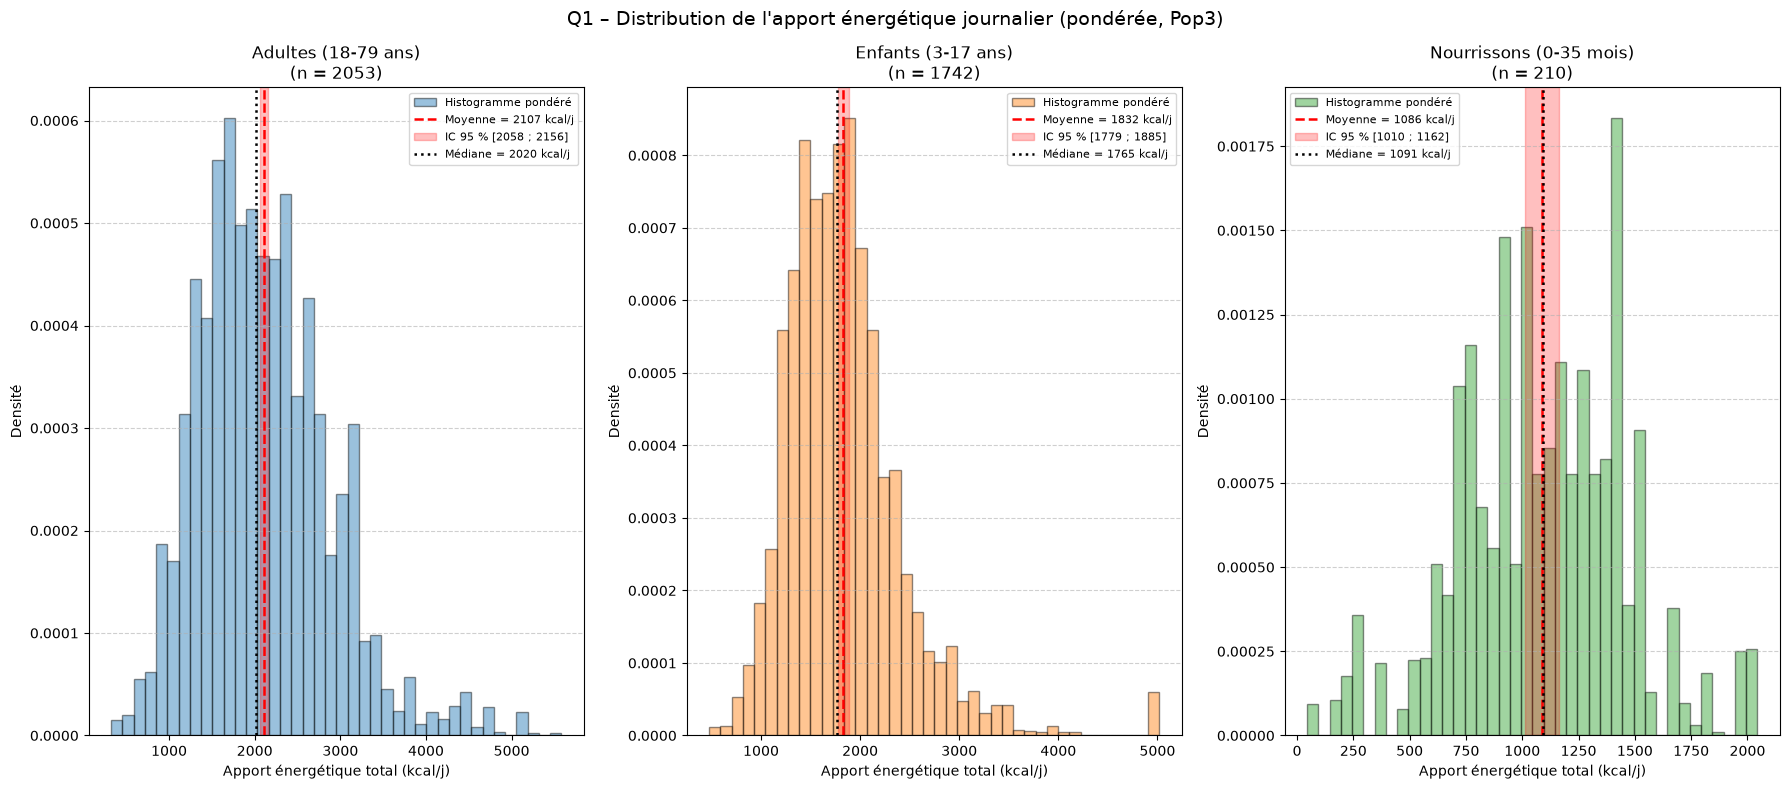

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax, (nom, (d, pond, couleur)) in zip(axes, groupes_q1.items()):
    d = d.dropna(subset=[VAR_E, pond])
    d = d[d[pond] > 0]
    y, w = d[VAR_E].to_numpy(float), d[pond].to_numpy(float)

    # histogramme pondéré (densité)
    ax.hist(y, bins=40, weights=w, density=True, color=couleur,
            alpha=0.45, edgecolor="black", label="Histogramme pondéré")

    # moyenne, IC 95 %, médiane
    s = tableau_q1.loc[nom]
    ax.axvline(s["Moyenne"], color="red", ls="--", lw=1.8,
               label=f"Moyenne = {s['Moyenne']:.0f} kcal/j")
    ax.axvspan(s["IC95% inf"], s["IC95% sup"], color="red", alpha=0.25,
               label=f"IC 95 % [{s['IC95% inf']:.0f} ; {s['IC95% sup']:.0f}]")
    ax.axvline(s["Médiane"], color="black", ls=":", lw=1.8,
               label=f"Médiane = {s['Médiane']:.0f} kcal/j")

    ax.set_title(f"{nom}\n(n = {int(s['n (non pondéré)'])})")
    ax.set_xlabel("Apport énergétique total (kcal/j)")
    ax.set_ylabel("Densité")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(fontsize=8)

fig.suptitle("Q1 – Distribution de l'apport énergétique journalier (pondérée, Pop3)", fontsize=14)
plt.tight_layout()
plt.show()

**Q2 — Sexe :**
Comment les apports nutritionnels diffèrent-ils selon le sexe ?  

Nous nous basons sur la même logique que la question 1 mais en séparant par sexe en plus de par âge.

In [21]:
df_ad_wm = df_adulte[df_adulte['sex_PS'] == 2].copy()
df_ad_m = df_adulte[df_adulte['sex_PS'] == 1].copy()
df_en_wm = df_enfant[df_enfant['sex_PS'] == 2].copy()
df_en_m = df_enfant[df_enfant['sex_PS'] == 1].copy()
df_nr_wm = df_nourisson[df_nourisson['sex_PS'] == 2].copy()
df_nr_m = df_nourisson[df_nourisson['sex_PS'] == 1].copy()



groupes_q2 = {
    "Adultes femme (18-79 ans)":      (df_ad_wm,    "pond_indiv_adu_pop3", "tab:blue"),
    "Adultes homme (18-79 ans)":      (df_ad_m,    "pond_indiv_adu_pop3", "tab:blue"),
    "Enfants femme (3-17 ans)":       (df_en_wm,    "pond_indiv_enf_pop3", "tab:orange"),
    "Enfants homme (3-17 ans)":       (df_en_m,    "pond_indiv_enf_pop3", "tab:orange"),
    "Nourrissons femme (0-35 mois)":  (df_nr_wm, "pond_indiv_enf_pop3", "tab:green"),
    "Nourrissons homme (0-35 mois)":  (df_nr_m, "pond_indiv_enf_pop3", "tab:green"),
}

tableau_q2 = pd.DataFrame({
    nom: stats_descriptives_ponderees(d, VAR_E, pond)
    for nom, (d, pond, _) in groupes_q2.items()
}).T
print("Apport énergétique journalier (kcal/j) – statistiques pondérées")
display(tableau_q2.round(1))

Apport énergétique journalier (kcal/j) – statistiques pondérées


,n (non pondéré),Moyenne,IC95% inf,IC95% sup,Écart-type,Min,Médiane,Max
Adultes femme (18-79 ans),1192.0,1793.5,1741.5,1845.5,583.8,323.1,1725.5,5582.4
Adultes homme (18-79 ans),861.0,2438.5,2356.2,2520.8,798.0,439.7,2386.8,5215.2
Enfants femme (3-17 ans),859.0,1717.5,1613.4,1821.6,596.3,476.3,1637.4,5020.7
Enfants homme (3-17 ans),883.0,1941.2,1898.5,1983.9,545.8,618.3,1883.8,4143.3
Nourrissons femme (0-35 mois),99.0,1045.5,940.2,1150.8,389.4,160.3,987.3,2013.5
Nourrissons homme (0-35 mois),111.0,1126.3,1037.7,1215.0,344.1,44.8,1148.7,2044.4


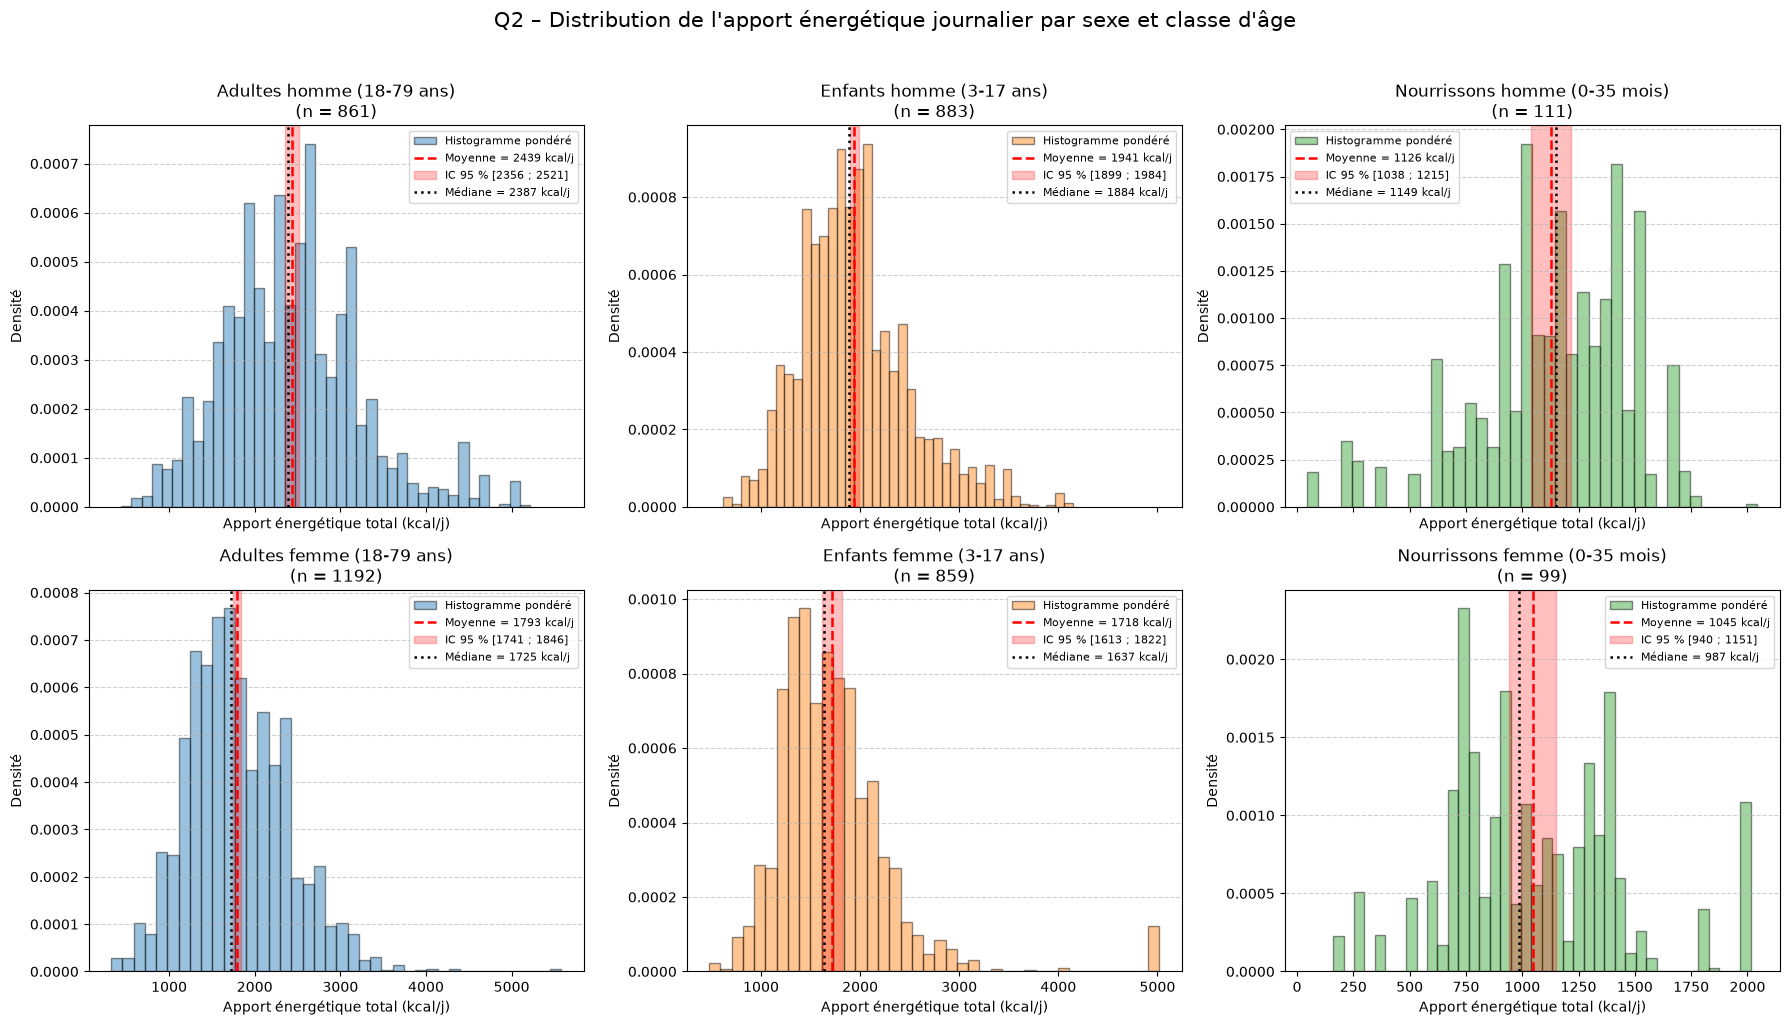

In [22]:
# Ordre souhaité : hommes sur la 1re ligne, femmes sur la 2e
ordre_groupes = [
    "Adultes homme (18-79 ans)",
    "Enfants homme (3-17 ans)",
    "Nourrissons homme (0-35 mois)",
    "Adultes femme (18-79 ans)",
    "Enfants femme (3-17 ans)",
    "Nourrissons femme (0-35 mois)",
]

# Créer une figure de 2 lignes x 3 colonnes
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10),
    sharex="col"  # Même échelle X pour hommes/femmes d'une même classe d'âge
)

for i, nom in enumerate(ordre_groupes):
    ligne = 0 if "homme" in nom else 1
    colonne = (
        0 if nom.startswith("Adultes")
        else 1 if nom.startswith("Enfants")
        else 2
    )
    ax = axes[ligne, colonne]

    d, pond, couleur = groupes_q2[nom]
    d = d.dropna(subset=[VAR_E, pond])
    d = d[d[pond] > 0]

    y = d[VAR_E].to_numpy(float)
    w = d[pond].to_numpy(float)

    # Histogramme pondéré
    ax.hist(
        y, bins=40, weights=w, density=True,
        color=couleur, alpha=0.45, edgecolor="black",
        label="Histogramme pondéré"
    )

    # Statistiques correspondantes
    s = tableau_q2.loc[nom]

    ax.axvline(
        s["Moyenne"], color="red", ls="--", lw=1.8,
        label=f"Moyenne = {s['Moyenne']:.0f} kcal/j"
    )

    ax.axvspan(
        s["IC95% inf"], s["IC95% sup"],
        color="red", alpha=0.25,
        label=f"IC 95 % [{s['IC95% inf']:.0f} ; {s['IC95% sup']:.0f}]"
    )

    ax.axvline(
        s["Médiane"], color="black", ls=":", lw=1.8,
        label=f"Médiane = {s['Médiane']:.0f} kcal/j"
    )

    ax.set_title(f"{nom}\n(n = {int(s['n (non pondéré)'])})")
    ax.set_xlabel("Apport énergétique total (kcal/j)")
    ax.set_ylabel("Densité")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(fontsize=8)

fig.suptitle(
    "Q2 – Distribution de l'apport énergétique journalier par sexe et classe d'âge",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()


**Q3 — Âge :**
Comment évoluent les apports nutritionnels avec l'âge ?  

Cette fois ci on sépare les populations en tranche d'âge.  
Rappel : 
- Adulte : "tage_PS" entre 7 et 9
- Enfant : "tage_PS" entre 3 et 6
- Nourisson : "tage_PS" entre 1 et 2


In [23]:
df_ad_7 = df_adulte[df_adulte['tage_PS'] == 7].copy()
df_ad_8 = df_adulte[df_adulte['tage_PS'] == 8].copy()
df_ad_9 = df_adulte[df_adulte['tage_PS'] == 9].copy()
df_en_3 = df_enfant[df_enfant['tage_PS'] == 3].copy()
df_en_4 = df_enfant[df_enfant['tage_PS'] == 4].copy()
df_en_5 = df_enfant[df_enfant['tage_PS'] == 5].copy()
df_en_6 = df_enfant[df_enfant['tage_PS'] == 6].copy()
df_nr_1 = df_nourisson[df_nourisson['tage_PS'] == 1].copy()
df_nr_2 = df_nourisson[df_nourisson['tage_PS'] == 2].copy()


groupes_q3 = {
    "Nourrissons (0-11 mois)":  (df_nr_1, "pond_indiv_enf_pop3", "tab:green"),
    "Nourrissons (1-3 ans)":  (df_nr_2, "pond_indiv_enf_pop3", "tab:green"),
    "Enfants (4-6 ans)":       (df_en_3,    "pond_indiv_enf_pop3", "tab:orange"),
    "Enfants (7-10 ans)":       (df_en_4,    "pond_indiv_enf_pop3", "tab:orange"),
    "Enfants (11-14 ans)":       (df_en_5,    "pond_indiv_enf_pop3", "tab:orange"),
    "Enfants (15-17 ans)":       (df_en_6,    "pond_indiv_enf_pop3", "tab:orange"),
    "Adultes (18-44 ans)":      (df_ad_7,    "pond_indiv_adu_pop3", "tab:blue"),
    "Adultes (45-64 ans)":      (df_ad_8,    "pond_indiv_adu_pop3", "tab:blue"),
    "Adultes (65-79 ans)":      (df_ad_9,    "pond_indiv_adu_pop3", "tab:blue"),
}

tableau_q3 = pd.DataFrame({
    nom: stats_descriptives_ponderees(d, VAR_E, pond)
    for nom, (d, pond, _) in groupes_q3.items()
}).T
print("Apport énergétique journalier (kcal/j) – statistiques pondérées")
display(tableau_q3.round(1))

Apport énergétique journalier (kcal/j) – statistiques pondérées


,n (non pondéré),Moyenne,IC95% inf,IC95% sup,Écart-type,Min,Médiane,Max
Nourrissons (0-11 mois),51.0,647.3,555.1,739.5,268.7,44.8,683.9,1189.0
Nourrissons (1-3 ans),159.0,1199.4,1125.4,1273.5,301.0,585.4,1183.7,2044.4
Enfants (4-6 ans),345.0,1525.2,1479.2,1571.1,352.9,769.3,1479.7,3401.3
Enfants (7-10 ans),481.0,1829.6,1772.5,1886.7,415.8,914.2,1801.7,3598.6
Enfants (11-14 ans),523.0,2036.6,1889.1,2184.1,681.0,634.5,1938.7,5020.7
Enfants (15-17 ans),393.0,1883.2,1792.7,1973.8,686.6,476.3,1823.0,4143.3
Adultes (18-44 ans),753.0,2194.0,2106.4,2281.5,803.6,323.1,2076.5,5582.4
Adultes (45-64 ans),804.0,2093.8,1996.1,2191.4,734.4,539.2,1978.4,5060.8
Adultes (65-79 ans),496.0,1904.0,1832.4,1975.5,692.2,326.2,1815.0,4983.0


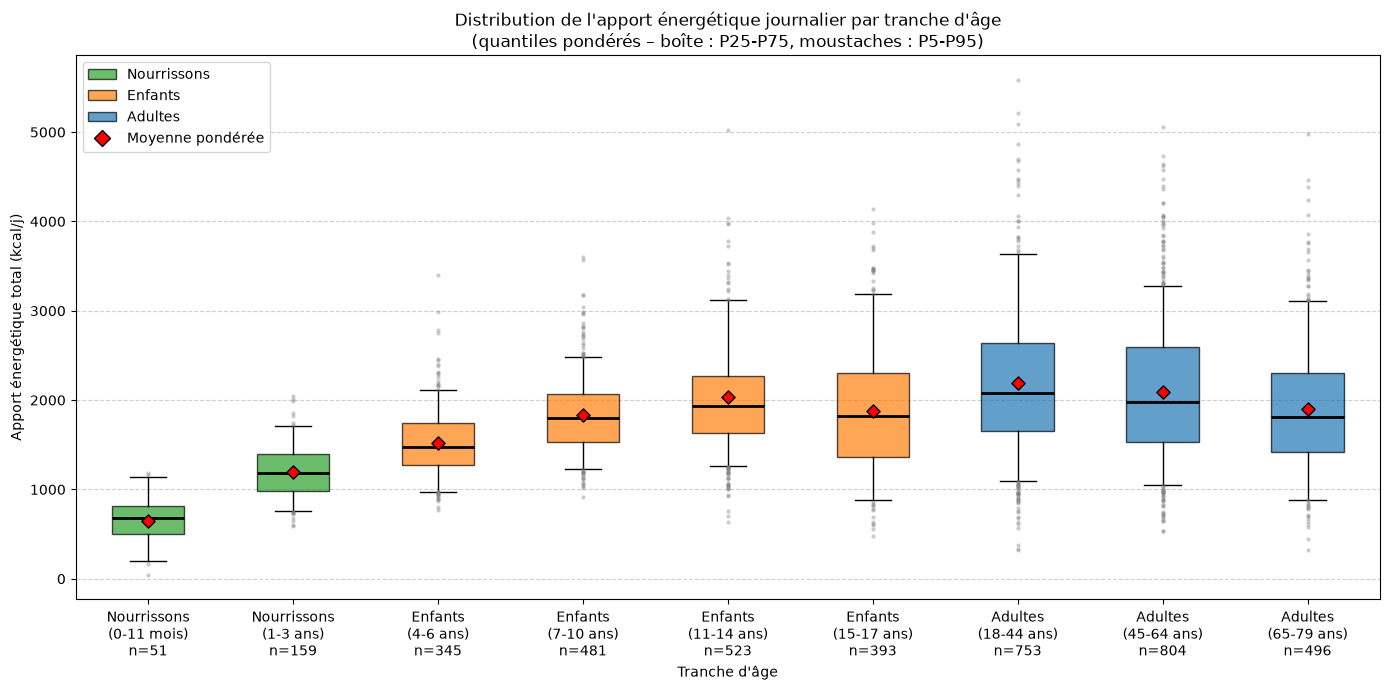

In [24]:
boites, couleurs_b = [], []

for nom, (d, pond, couleur) in groupes_q3.items():
    d = d.dropna(subset=[VAR_E, pond])
    d = d[d[pond] > 0]
    y, w = d[VAR_E].to_numpy(float), d[pond].to_numpy(float)
    p5, p25, med, p75, p95 = quantile_pondere(y, w, [0.05, 0.25, 0.5, 0.75, 0.95])

    categorie, tranche = nom.split(" (")
    boites.append({
        "label": f"{categorie}\n({tranche}\nn={len(d)}",
        "whislo": p5, "q1": p25, "med": med, "q3": p75, "whishi": p95,
        "fliers": y[(y < p5) | (y > p95)],
    })
    couleurs_b.append(couleur)

fig, ax = plt.subplots(figsize=(14, 7))

bp = ax.bxp(boites, patch_artist=True, showfliers=True,
            boxprops=dict(edgecolor="black"),
            medianprops=dict(color="black", lw=2),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black"),
            flierprops=dict(marker="o", markersize=3, markerfacecolor="grey",
                            markeredgecolor="none", alpha=0.4))

for patch, c in zip(bp["boxes"], couleurs_b):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)


ax.scatter(np.arange(1, len(tableau_q3) + 1), tableau_q3["Moyenne"],
           marker="D", color="red", edgecolor="black", zorder=5, s=45)

ax.set_xlabel("Tranche d'âge")
ax.set_ylabel("Apport énergétique total (kcal/j)")
ax.set_title("Distribution de l'apport énergétique journalier par tranche d'âge\n"
             "(quantiles pondérés – boîte : P25-P75, moustaches : P5-P95)")
ax.grid(axis="y", linestyle="--", alpha=0.6)

handles = [Patch(facecolor="tab:green",  edgecolor="black", alpha=0.7, label="Nourrissons"),
           Patch(facecolor="tab:orange", edgecolor="black", alpha=0.7, label="Enfants"),
           Patch(facecolor="tab:blue",   edgecolor="black", alpha=0.7, label="Adultes"),
           Line2D([0], [0], marker="D", color="w", markerfacecolor="red",
                  markeredgecolor="black", markersize=8, label="Moyenne pondérée")]
ax.legend(handles=handles, loc="upper left")

plt.tight_layout()
plt.show()

**Q4 — Densité nutritionnelle :**
Comment comparer les apports nutritionnels à énergie comparable ?  

1. truc de base
- 5 nutriment3 NUM Protéines (g/j)
- 6 nutriment4 NUM Glucides (g/j)
- 7 nutriment5 NUM Sucres (g/j)
- 8 nutriment6 NUM Amidon (g/j)
- 10 nutriment8 NUM Fibres (g/j)
- 12 nutriment10 NUM Lipides (g/j)
- 13 nutriment11 NUM Acides gras saturés (AGS) (g/j)
1. minéraux
- 32 nutriment30 NUM Sodium (mg/j)
- 34 nutriment32 NUM Magnésium (mg/j)
- 35 nutriment33 NUM Phosphore (mg/j)
- 36 nutriment34 NUM Potassium (mg/j)
- 37 nutriment35 NUM Calcium (mg/j)
1. Vitamine
- 53 nutriment51 NUM Vitamine C (mg/j)
- 54 nutriment52 NUM Vitamine D (μg/j)
- 55 nutriment53 NUM Vitamine E (mg/j)

In [25]:
groupe_q4 = {
    "Adultes (18-79 ans)":      (df_adulte,    "pond_indiv_adu_pop3", "tab:blue"),
    "Enfants (3-17 ans)":       (df_enfant,    "pond_indiv_enf_pop3", "tab:orange"),
    "Nourrissons (0-35 mois)":  (df_nourisson, "pond_indiv_enf_pop3", "tab:green"),
}

dic_nutriments = {
    # Nutriments de base
    "nutriment3": "Protéines (g/j)",
    "nutriment4": "Glucides (g/j)",
    "nutriment5": "Sucres (g/j)",
    "nutriment6": "Amidon (g/j)",
    "nutriment8": "Fibres (g/j)",
    "nutriment10": "Lipides (g/j)",
    "nutriment11": "Acides gras saturés (AGS) (g/j)",
    # Minéraux
    "nutriment30": "Sodium (mg/j)",
    "nutriment32": "Magnésium (mg/j)",
    "nutriment33": "Phosphore (mg/j)",
    "nutriment34": "Potassium (mg/j)",
    "nutriment35": "Calcium (mg/j)",
    # Vitamines
    "nutriment51": "Vitamine C (mg/j)",
    "nutriment52": "Vitamine D (μg/j)",
    "nutriment53": "Vitamine E (mg/j)"
}

for nom, (d, pond, couleur) in groupe_q4.items():
    for nut in dic_nutriments : 
        d[f'rap_{nut}'] = d[nut] * 1000 / d[VAR_E]


# ---------- Moyenne pondérée + IC 95 % de chaque rapport, par groupe ----------
resultats = {}   # (groupe, nut) -> (moy, ic_inf, ic_sup)
for g, (d, pond, _) in groupe_q4.items():
    for nut in dic_nutriments:
        var = f"rap_{nut}"
        dd = d.dropna(subset=[var, pond, "strate", "zae"])
        dd = dd[(dd[pond] > 0) & np.isfinite(dd[var])]
        moy, se, lo, hi = ic95_moyenne_plan_sondage(dd, var, pond)
        resultats[(g, nut)] = (moy, lo, hi)

C:\Users\theob\AppData\Local\Temp\ipykernel_22648\872583072.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d[f'rap_{nut}'] = d[nut] * 1000 / d[VAR_E]


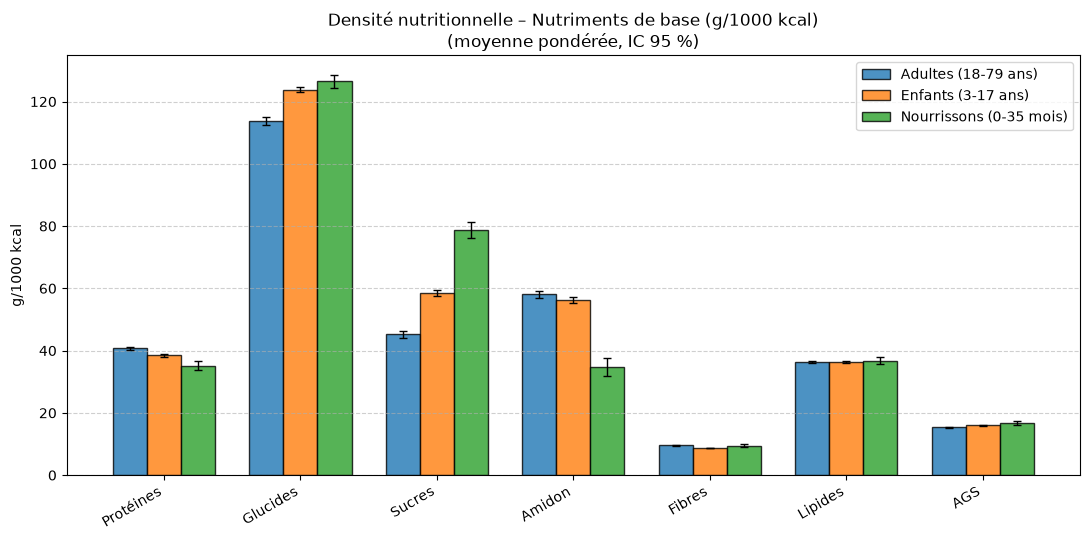

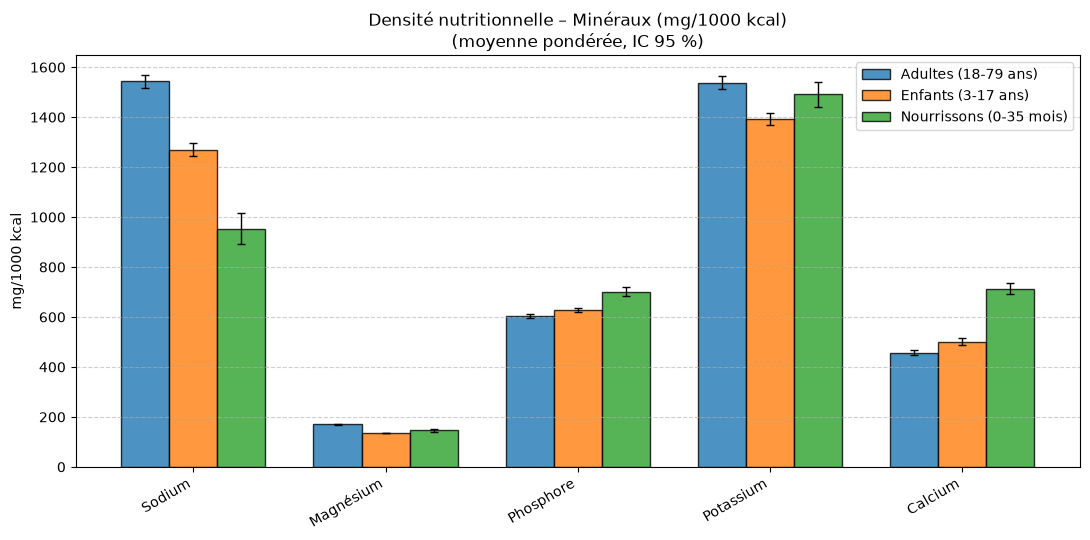

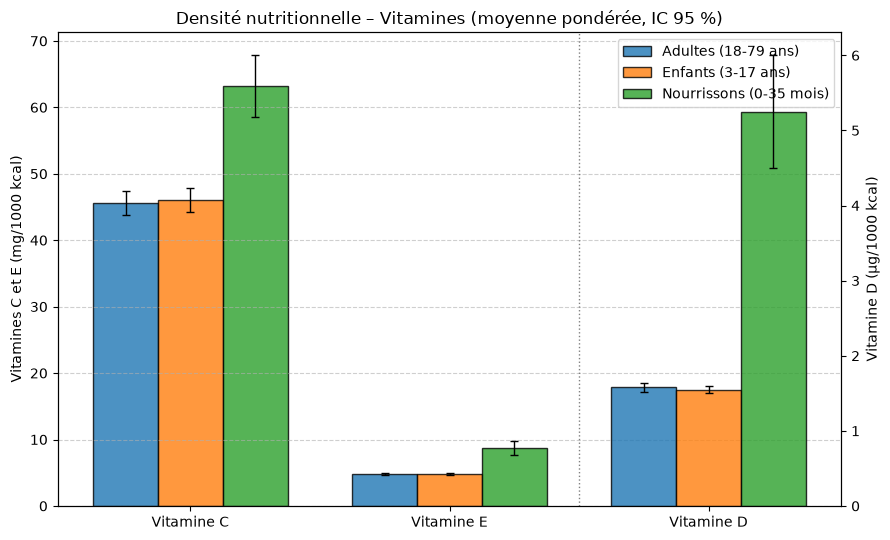

In [26]:
ensembles = {
    "Nutriments de base (g/1000 kcal)": ["nutriment3", "nutriment4", "nutriment5", "nutriment6",
                                          "nutriment8", "nutriment10", "nutriment11"],
    "Minéraux (mg/1000 kcal)":          ["nutriment30", "nutriment32", "nutriment33",
                                          "nutriment34", "nutriment35"],
    "Vitamines":                        ["nutriment51", "nutriment53", "nutriment52"],  # C, E (mg) | D (µg)
}

def nom_court(nut):
    return dic_nutriments[nut].split(" (")[0] if "AGS" not in dic_nutriments[nut] else "AGS"


# ---------- Fonction de tracé d'une série de barres ----------
def barres(ax, nuts, decalage_x=0, largeur=0.25, n_total=None):
    n_total = n_total or len(nuts)
    for i, (g, (_, _, couleur)) in enumerate(groupe_q4.items()):
        m  = np.array([resultats[(g, n)][0] for n in nuts])
        lo = np.array([resultats[(g, n)][1] for n in nuts])
        hi = np.array([resultats[(g, n)][2] for n in nuts])
        x = decalage_x + np.arange(len(nuts)) + (i - 1) * largeur
        ax.bar(x, m, width=largeur, color=couleur, edgecolor="black", alpha=0.8,
               yerr=[m - lo, hi - m], capsize=3, error_kw={"elinewidth": 1})

legende = [Patch(facecolor=c, edgecolor="black", alpha=0.8, label=g)
           for g, (_, _, c) in groupe_q4.items()]

# ---------- Figures 1 et 2 : base et minéraux  ----------
for titre in list(ensembles)[:2]:
    nuts = ensembles[titre]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    barres(ax, nuts)
    ax.set_xticks(np.arange(len(nuts)))
    ax.set_xticklabels([nom_court(n) for n in nuts], rotation=30, ha="right")
    ax.set_ylabel(titre.split("(")[1].rstrip(")"))
    ax.set_title(f"Densité nutritionnelle – {titre}\n(moyenne pondérée, IC 95 %)")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.legend(handles=legende)
    plt.tight_layout()
    plt.show()

# ---------- Figure 3 : vitamines ----------
vit_mg, vit_ug = ["nutriment51", "nutriment53"], ["nutriment52"]
fig, ax1 = plt.subplots(figsize=(9, 5.5))
ax2 = ax1.twinx()

barres(ax1, vit_mg, decalage_x=0)    # C, E
barres(ax2, vit_ug, decalage_x=2)    # D

ax1.set_xticks([0, 1, 2])
ax1.set_xticklabels([nom_court(n) for n in vit_mg + vit_ug])
ax1.set_ylabel("Vitamines C et E (mg/1000 kcal)")
ax2.set_ylabel("Vitamine D (µg/1000 kcal)")
ax1.axvline(1.5, color="grey", ls=":", lw=1)
ax1.set_title("Densité nutritionnelle – Vitamines (moyenne pondérée, IC 95 %)")
ax1.grid(axis="y", linestyle="--", alpha=0.6)
ax1.legend(handles=legende, loc="upper right")
plt.tight_layout()
plt.show()

**Q5 — Contributeurs :**
Quels sont les principaux aliments contribuant aux apports en protéines ?  
 --> Répéter l’analyse pour : calcium ; fer ; fibres ; vitamine C


**Q6 — Variabilité :** Quelle est la variabilité interindividuelle des apports au sein d’un
même groupe (par exemple chez les femmes 25 - 44 ans) ?  

**Questions bonus**

Pour aller plus loin (niveau bonus)

1. Profils alimentaires (Q_Profils_alimentaires)  
Existe-t-il des profils alimentaires distincts (par exemple, une alimentation riche en produits sucrés ou en produits végétaux) ?

2. Diversité alimentaire (Q_Divers)  
Les personnes ayant une consommation énergétique élevée ont-elles également une alimentation plus diversifiée ?

3. Comparabilité des enquêtes de consommation (Q_Comp_Conso)  
Comment comparer entre elles les enquêtes de consommation, compte tenu des différences de :  
population ;  
périodes d'enquête ;  
nomenclatures ;  
méthodes de collecte ;  
groupes d'âge ;  
définition des aliments.  

4. Évolution temporelle des habitudes alimentaires (Q_Evolution_Temporelle)  
Comment les habitudes alimentaires ont-elles évolué entre INCA 1, INCA 2 et INCA 3 (par exemple, en matière de consommation de fruits, de légumes et de poisson) ?

5. Mapping entre INCA et Ciqual (Q_Mapping_INCA_CIQUAL)  
Comment automatiser la mise en correspondance (mapping) entre les aliments de l'enquête et les aliments de la base Ciqual ?